# 02 · Thử nghiệm thuật toán và học tổ hợp

Nhóm 13 · Bài kiểm tra 3 · Tiêu chí 4

So sánh Logistic Regression, CART, SVM tuyến tính, Random Forest,
HistGradientBoosting và Stacking trên cùng 5 fold. Chọn theo
ROC-AUC, đồng thời xem Accuracy và F1-Macro.

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, display

for directory in (Path.cwd(), Path.cwd() / "code"):
    if (directory / "workflow_kt3.py").is_file():
        sys.path.insert(0, str(directory))
        break

from workflow_kt3 import ROOT, SUMMARY_PATH, load_splits

train, validation, test = load_splits()
with SUMMARY_PATH.open(encoding="utf-8") as summary_file:
    summary = json.load(summary_file)

CART tạo các ngưỡng phân nhánh. SVM tuyến tính học biên phân lớp qua
hinge loss. Random Forest lấy trung bình nhiều cây để giảm biến động.
HistGradientBoosting thêm cây tuần tự theo gradient của hàm mất mát.
Stacking huấn luyện Logistic Regression tầng hai trên các dự đoán OOF
từ Random Forest, HGB và Logistic Regression. Các mô hình tầng một
đều có tiền xử lý riêng trong từng fold OOF.

,Mô hình,CV ROC-AUC,CV ROC-AUC std,CV Accuracy,CV F1-Macro
7,"HistGradientBoosting + FE, tối ưu",0.98366,0.00113,0.92763,0.92679
5,"HistGradientBoosting, đặc trưng gốc",0.98360,0.00122,0.92780,0.92691
6,HistGradientBoosting + FE,0.98337,0.00114,0.92797,0.92711
8,Stacking (RF + HGB + Logistic),0.98260,0.00123,0.92760,0.92678
4,Random Forest,0.96846,0.00142,0.90046,0.89896
1,Logistic Regression + FE,0.94661,0.00229,0.86869,0.86705
0,Logistic Regression (KT2),0.94567,0.00238,0.86674,0.86509
3,SVM tuyến tính (SGD hinge),0.94293,0.00293,0.86317,0.86114
2,Decision Tree (CART),0.94068,0.00202,0.87471,0.87282


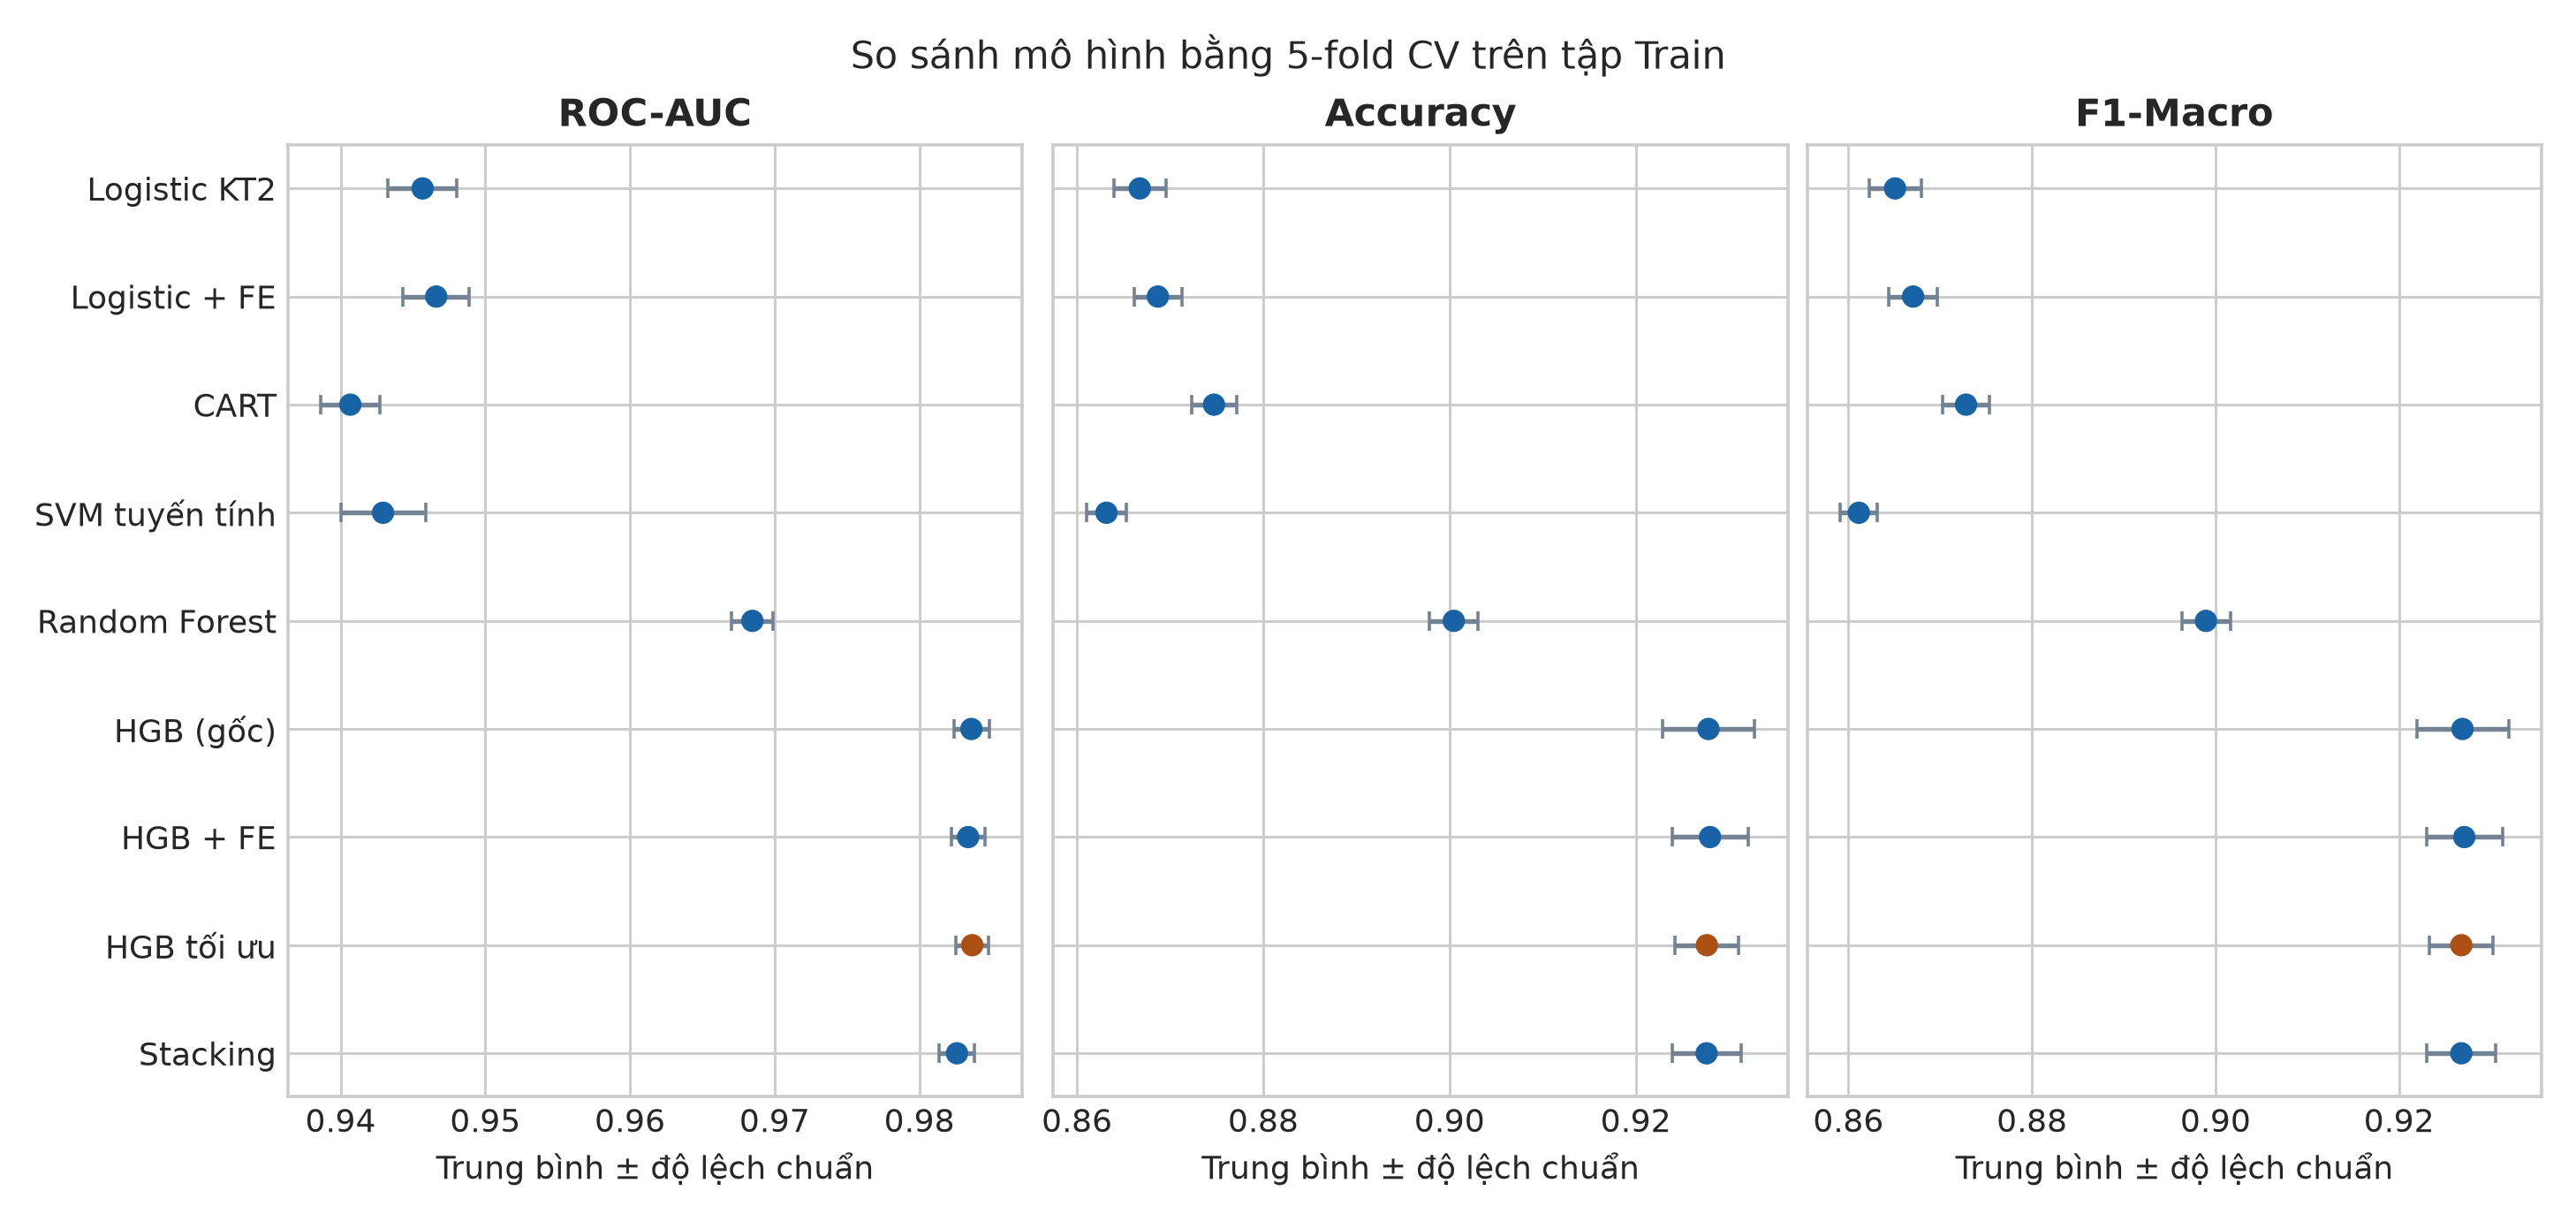

In [2]:
result = pd.DataFrame(summary["cv_results"])
columns = ["Mô hình", "CV ROC-AUC", "CV ROC-AUC std", "CV Accuracy", "CV F1-Macro"]
display(result[columns].sort_values("CV ROC-AUC", ascending=False).round(5))
display(Image(filename=str(ROOT / "images" / "so_sanh_mo_hinh_kt2_vs_kt3.png"), width=960))

## Chạy lại một đối chứng trong notebook

Đo CART với đúng pipeline, Train và các fold từ script. Các mô hình
tốn thời gian hơn được chạy trong script chính và hiện ở bảng trên.

In [3]:
import numpy as np
from sklearn.model_selection import cross_val_score
from threadpoolctl import threadpool_limits
from workflow_kt3 import make_candidates, stratified_cv

cart = make_candidates(train.X.columns)["cart"]
with threadpool_limits(1):
    scores = cross_val_score(cart, train.X, train.y, cv=stratified_cv(), scoring="roc_auc")
stored_scores = next(row for row in summary["cv_results"] if row["id"] == "cart")
display(pd.DataFrame({"Fold": range(1, len(scores) + 1), "ROC-AUC": scores}).round(5))
np.testing.assert_allclose(scores, stored_scores["Fold ROC-AUC"], atol=1e-8)

,Fold,ROC-AUC
0,1,0.93742
1,2,0.94035
2,3,0.94316
3,4,0.94001
4,5,0.94244
